# The cos(2 phi) transmon (notes Appendix B.3)

Each step follows the notes; equation labels are given in comments.

In [1]:
import sympy as sym
import circuit_quantization as cq
from circuit_quantization import Branch, Circuit, Loops, quantize

sym.init_printing()
F, H, W = cq.ghz_to_farad, cq.ghz_to_henry, cq.phase_to_weber

In [2]:
ECS, EC1, EC2, EL1, EL2, EJ1, EJ2 = sym.symbols("E_CS E_CJ1 E_CJ2 E_L1 E_L2 E_J1 E_J2", positive=True)
vext = sym.Symbol("varphi_ext", real=True)
circuit = Circuit([
    Branch("CS", 1, 4, C=F(ECS)),
    Branch("J1", 1, 2, C=F(EC1), EJ=EJ1),
    Branch("J2", 1, 3, C=F(EC2), EJ=EJ2),
    Branch("L1", 2, 4, L=H(EL1)),
    Branch("L2", 3, 4, L=H(EL2)),
], ground=4)
cycles = {"kite": {"J1": 1, "J2": -1, "L1": 1, "L2": -1}, "cb": {"CS": 1, "J1": -1, "L1": -1}}  # eq:kite_G
loops = Loops(circuit, cycles, {"kite": W(vext), "cb": 0})
Z = sym.Matrix([[1, 0, 0], [0, 1, 1], [0, -1, 1]])  # eq:kite_Z
res = quantize(circuit, loops, Z, ("c", "e", "e"))
res

Result(circuit=Circuit(branches=(Branch(name='CS', tail=1, head=4, C=e**2/(2*E_CS*h), L=None, EJ=None, V=None), Branch(name='J1', tail=1, head=2, C=e**2/(2*E_CJ1*h), L=None, EJ=E_J1, V=None), Branch(name='J2', tail=1, head=3, C=e**2/(2*E_CJ2*h), L=None, EJ=E_J2, V=None), Branch(name='L1', tail=2, head=4, C=0, L=Phi_0**2/(4*pi**2*E_L1*h), EJ=None, V=None), Branch(name='L2', tail=3, head=4, C=0, L=Phi_0**2/(4*pi**2*E_L2*h), EJ=None, V=None)), ground=4, t=t), loops=<circuit_quantization.circuit.Loops object at 0x128bda5d0>, lag=Lagrangian(Omega=Matrix([
[ 1,  1,  1,  0,  0],
[ 0, -1,  0,  1,  0],
[ 0,  0, -1,  0,  1],
[-1,  0,  0, -1, -1]]), Omega_int=Matrix([
[1,  1,  1, 0, 0],
[0, -1,  0, 1, 0],
[0,  0, -1, 0, 1]]), C_b=Matrix([
[e**2/(2*E_CS*h),                0,                0, 0, 0],
[              0, e**2/(2*E_CJ1*h),                0, 0, 0],
[              0,                0, e**2/(2*E_CJ2*h), 0, 0],
[              0,                0,                0, 0, 0],
[              0, 

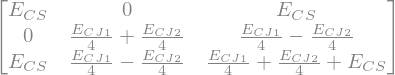

In [3]:
res.ham.E_C

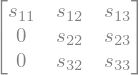

In [4]:
cq.residual_freedom(res.coords)